# Vélib' Métropole : une station sera-t-elle vide dans 30 minutes ?

**DATA-IA-EXE710 · Télécom Paris · Kit Data Science**

Dans ce notebook, on analyse les instantanés Vélib' que notre collecteur enregistre toutes les 5 minutes environ (dossier `data/raw/`). Toutes les données sont réelles : il suffit de relancer le notebook à la fin de la collecte pour mettre à jour les résultats.

**Plan**
1. Chargement des données
2. Couverture de la collecte
3. Qualité des données
4. Le champ `last_reported`
5. Exploration
6. Construction de la cible « vide dans 30 min »
7. Modèles et évaluation
8. Conclusion et limites

**Définitions**
- une station est **en service** si `is_renting == 1` ;
- une station est **vide** si elle est en service et que `num_bikes_available == 0` ;
- la **cible** vaut 1 si la station est en service maintenant et dans 30 minutes, et qu'elle n'a plus aucun vélo dans 30 minutes.

## 1. Chargement des données

In [1]:
# Récupérer le dépôt GitHub (dans Colab) ou utiliser le dossier local.
import os

if os.path.exists("../data/raw"):           # notebook lancé depuis le dossier notebooks/
    DOSSIER = ".."
elif os.path.exists("data/raw"):            # notebook lancé depuis la racine du dépôt
    DOSSIER = "."
else:                                       # Colab : on clone le dépôt
    if not os.path.exists("velib-kit-data-science"):
        os.system("git clone --depth 1 https://github.com/G-Akram01/velib-kit-data-science.git")
    DOSSIER = "velib-kit-data-science"

print("Dossier du projet :", DOSSIER)

Dossier du projet : ..


In [2]:
import glob
import gzip
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Les dates sont stockées en UTC ; les graphiques s'affichent en heure de Paris.
plt.rcParams["timezone"] = "Europe/Paris"
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

BLEU = "#2a78d6"
ORANGE = "#eb6834"
GRIS = "#8a8984"

In [3]:
def lire_json_gz(chemin):
    with gzip.open(chemin, "rt", encoding="utf-8") as f:
        return json.load(f)


def nb_velos_type(liste_types, type_velo):
    """Extrait le nombre de vélos 'mechanical' ou 'ebike' de num_bikes_available_types."""
    if not isinstance(liste_types, list):
        return np.nan
    for element in liste_types:
        if type_velo in element:
            return element[type_velo]
    return np.nan


fichiers = sorted(glob.glob(f"{DOSSIER}/data/raw/*/*.json.gz"))
print("Nombre de fichiers :", len(fichiers))

morceaux = []
for chemin in fichiers:
    contenu = lire_json_gz(chemin)
    stations = pd.DataFrame(contenu["stations"])
    stations["collecte"] = contenu["collected_at_utc"]
    morceaux.append(stations)

df = pd.concat(morceaux, ignore_index=True)
print("Dimensions :", df.shape)
df.head()

Nombre de fichiers : 194


Dimensions : (294686, 13)


,station_id,num_bikes_available,numBikesAvailable,num_bikes_available_types,num_docks_available,numDocksAvailable,is_installed,is_returning,is_renting,last_reported,stationCode,station_opening_hours,collecte
0,213688169,2,2,"[{'mechanical': 1}, {'ebike': 1}]",33,33,1,1,1,1792861665,16107,None,2026-10-24T17:55:14+00:00
1,19179944124,26,26,"[{'mechanical': 24}, {'ebike': 2}]",1,1,1,1,1,1792861861,40001,None,2026-10-24T17:55:14+00:00
2,18795078746,2,2,"[{'mechanical': 1}, {'ebike': 1}]",26,26,1,1,1,1792861540,32304,None,2026-10-24T17:55:14+00:00
3,36255,3,3,"[{'mechanical': 0}, {'ebike': 3}]",18,18,1,1,1,1792862027,9020,None,2026-10-24T17:55:14+00:00
4,251039991,5,5,"[{'mechanical': 1}, {'ebike': 4}]",20,20,1,1,1,1792861766,14111,None,2026-10-24T17:55:14+00:00


In [4]:
# On garde les colonnes utiles avec des noms plus simples.
df["collecte"] = pd.to_datetime(df["collecte"], utc=True)
df["station_id"] = df["station_id"].astype(str)
df["velos_meca"] = df["num_bikes_available_types"].apply(lambda x: nb_velos_type(x, "mechanical"))
df["velos_elec"] = df["num_bikes_available_types"].apply(lambda x: nb_velos_type(x, "ebike"))

df = df.rename(columns={
    "num_bikes_available": "velos",
    "num_docks_available": "bornes_libres",
    "is_renting": "en_service",
})
df = df[["station_id", "collecte", "velos", "velos_meca", "velos_elec", "bornes_libres",
         "en_service", "is_installed", "is_returning", "last_reported"]]

# Le cron GitHub n'est pas à l'heure pile : on arrondit chaque relevé aux 5 minutes les plus proches.
df["temps"] = df["collecte"].dt.round("5min")
# Si deux relevés tombent sur le même créneau (lancement manuel), on garde le dernier.
df = df.sort_values("collecte").drop_duplicates(["station_id", "temps"], keep="last")
df.head()

,station_id,collecte,velos,velos_meca,velos_elec,bornes_libres,en_service,is_installed,is_returning,last_reported,temps
0,213688169,2026-10-24 17:55:14+00:00,2,1.0,1.0,33,1,1,1,1792861665,2026-10-24 17:55:00+00:00
1018,128834707,2026-10-24 17:55:14+00:00,11,11.0,0.0,10,1,1,1,1792862001,2026-10-24 17:55:00+00:00
1017,49423507,2026-10-24 17:55:14+00:00,69,48.0,21.0,4,1,1,1,1792862043,2026-10-24 17:55:00+00:00
1016,11908496227,2026-10-24 17:55:14+00:00,1,1.0,0.0,23,1,1,1,1792861901,2026-10-24 17:55:00+00:00
1015,54000537,2026-10-24 17:55:14+00:00,12,9.0,3.0,3,1,1,1,1792861783,2026-10-24 17:55:00+00:00


In [5]:
# Référentiel des stations : nom, position, capacité (on prend le fichier le plus récent).
fichiers_ref = sorted(glob.glob(f"{DOSSIER}/data/reference/station_information_*.json.gz"))
ref = pd.DataFrame(lire_json_gz(fichiers_ref[-1])["stations"])
ref["station_id"] = ref["station_id"].astype(str)
ref = ref[["station_id", "name", "lat", "lon", "capacity"]]
print("Stations dans le référentiel :", len(ref))
ref.head()

Stations dans le référentiel : 1519


,station_id,name,lat,lon,capacity
0,213688169,Benjamin Godard - Victor Hugo,48.865983,2.275725,35
1,19179944124,Hôpital Mondor,48.798922,2.453745,28
2,18795078746,Charcot - Benfleet,48.878370,2.440524,28
3,36255,Toudouze - Clauzel,48.879296,2.337360,21
4,251039991,Cassini - Denfert-Rochereau,48.837526,2.336035,25


## 2. Couverture de la collecte

Le flux Vélib' ne donne que l'état actuel des stations : si un relevé est manqué, il est perdu. Il faut donc vérifier combien de relevés on a vraiment et où sont les trous.

In [6]:
releves = pd.Series(sorted(df["temps"].unique()))
debut, fin = releves.min(), releves.max()
duree_heures = (fin - debut).total_seconds() / 3600
attendus = int(duree_heures * 60 / 5) + 1

print("Début :", debut.tz_convert("Europe/Paris"))
print("Fin   :", fin.tz_convert("Europe/Paris"))
print(f"Durée : {duree_heures:.1f} h")
print(f"Relevés attendus : {attendus} | relevés obtenus : {len(releves)} | couverture : {len(releves) / attendus:.1%}")

# Trous : écart de plus de 5 minutes entre deux relevés consécutifs.
ecarts = releves.diff().dt.total_seconds() / 60
trous = pd.DataFrame({"avant le trou": releves.shift(1).dt.tz_convert("Europe/Paris"),
                      "après le trou": releves.dt.tz_convert("Europe/Paris"),
                      "durée (min)": ecarts})
trous = trous[trous["durée (min)"] > 5].sort_values("durée (min)", ascending=False)
print("Nombre de trous :", len(trous), "| dont plus de 15 min :", (trous["durée (min)"] > 15).sum())
trous.head(10)

Début : 2026-10-24 19:55:00+02:00
Fin   : 2026-10-25 13:15:00+01:00
Durée : 18.3 h
Relevés attendus : 221 | relevés obtenus : 191 | couverture : 86.4%
Nombre de trous : 3 | dont plus de 15 min : 2


,avant le trou,après le trou,durée (min)
2,2026-10-24 20:10:00+02:00,2026-10-24 22:05:00+02:00,115.0
3,2026-10-24 22:05:00+02:00,2026-10-24 22:40:00+02:00,35.0
1,2026-10-24 19:55:00+02:00,2026-10-24 20:10:00+02:00,15.0


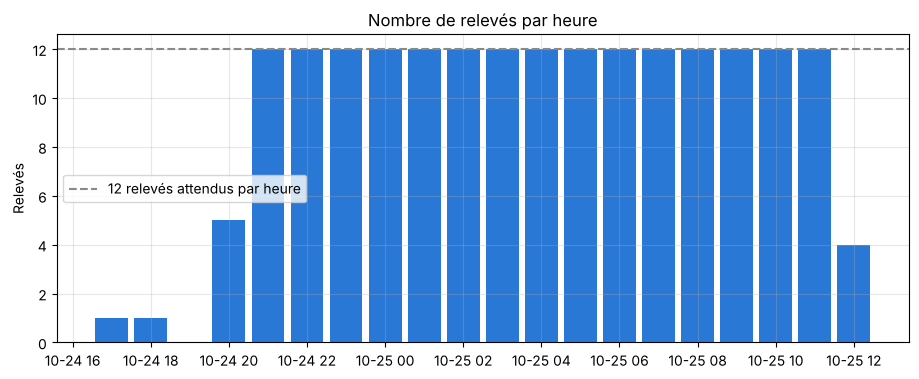

In [7]:
par_heure = releves.dt.floor("h").value_counts().sort_index()

plt.bar(par_heure.index, par_heure.values, width=0.035, color=BLEU)
plt.axhline(12, color=GRIS, linestyle="--", label="12 relevés attendus par heure")
plt.title("Nombre de relevés par heure")
plt.ylabel("Relevés")
plt.legend()
plt.show()

**Commentaire.** Le cron de GitHub Actions est prévu toutes les 5 minutes mais il n'est pas garanti : les relevés arrivent avec 1 à 3 minutes de retard (corrigé par l'arrondi) et il y a quelques trous, surtout au démarrage du workflow. Ces trous ne faussent pas les moyennes, mais on ne pourra pas calculer la cible « dans 30 min » pour les créneaux concernés.

## 3. Qualité des données

In [8]:
print("Stations par relevé :", df.groupby("temps")["station_id"].count().describe()[["min", "max"]].to_dict())
print("Stations différentes :", df["station_id"].nunique())
print("Stations absentes du référentiel :", len(set(df["station_id"]) - set(ref["station_id"])))
print()
print("Valeurs manquantes (%) :")
print((df.isna().mean() * 100).round(2))

Stations par relevé : {'min': 1519.0, 'max': 1519.0}
Stations différentes : 1519
Stations absentes du référentiel : 0

Valeurs manquantes (%) :
station_id       0.00
collecte         0.00
velos            0.00
velos_meca       3.14
velos_elec       3.14
bornes_libres    0.00
en_service       0.00
is_installed     0.00
is_returning     0.00
last_reported    0.00
temps            0.00
dtype: float64


In [9]:
print("Répartition de en_service (%) :")
print((df["en_service"].value_counts(normalize=True) * 100).round(2))

Répartition de en_service (%) :
en_service
1    89.06
0    10.94
Name: proportion, dtype: float64


In [10]:
# Stations "muettes" : aucune nouvelle depuis plus de 24 h au dernier relevé.
dernier = df[df["temps"] == fin].copy()
dernier["age_heures"] = (fin.timestamp() - dernier["last_reported"]) / 3600
muettes = dernier[dernier["age_heures"] > 24]
print("Stations muettes :", len(muettes), "| dont déclarées en service :", (muettes["en_service"] == 1).sum())

Stations muettes : 18 | dont déclarées en service : 1


In [11]:
# Vérifications de cohérence.
df = df.merge(ref[["station_id", "capacity"]], on="station_id", how="left")
print("vélos = mécaniques + électriques :", round((df["velos"] == df["velos_meca"] + df["velos_elec"]).mean() * 100, 1), "%")
print("vélos + bornes libres = capacité :", round((df["velos"] + df["bornes_libres"] == df["capacity"]).mean() * 100, 1), "%")
print("vélos + bornes libres < capacité :", round((df["velos"] + df["bornes_libres"] < df["capacity"]).mean() * 100, 1), "%")

vélos = mécaniques + électriques : 96.9 %
vélos + bornes libres = capacité : 51.7 %
vélos + bornes libres < capacité : 47.9 %


**Commentaire.**
- Le nombre de stations est le même à chaque relevé : le collecteur refuse les réponses incomplètes.
- Environ la moitié du temps, « vélos + bornes libres » est **inférieur** à la capacité : l'écart correspond aux bornes hors service. La capacité officielle surestime donc la place disponible.
- Quelques stations n'ont rien envoyé depuis plus de 24 h (parfois depuis des années) : on les retire pour ne pas les compter comme « vides ».

In [12]:
df = df[~df["station_id"].isin(muettes["station_id"])]
df["vide"] = ((df["velos"] == 0) & (df["en_service"] == 1)).astype(int)
df["pleine"] = ((df["bornes_libres"] == 0) & (df["en_service"] == 1)).astype(int)
print("Stations gardées :", df["station_id"].nunique())

Stations gardées : 1501


## 4. Le champ `last_reported`

On pourrait penser que `last_reported` donne l'heure de la dernière mise à jour de la station. On le vérifie en le comparant au nombre de stations dont le nombre de vélos change entre deux relevés.

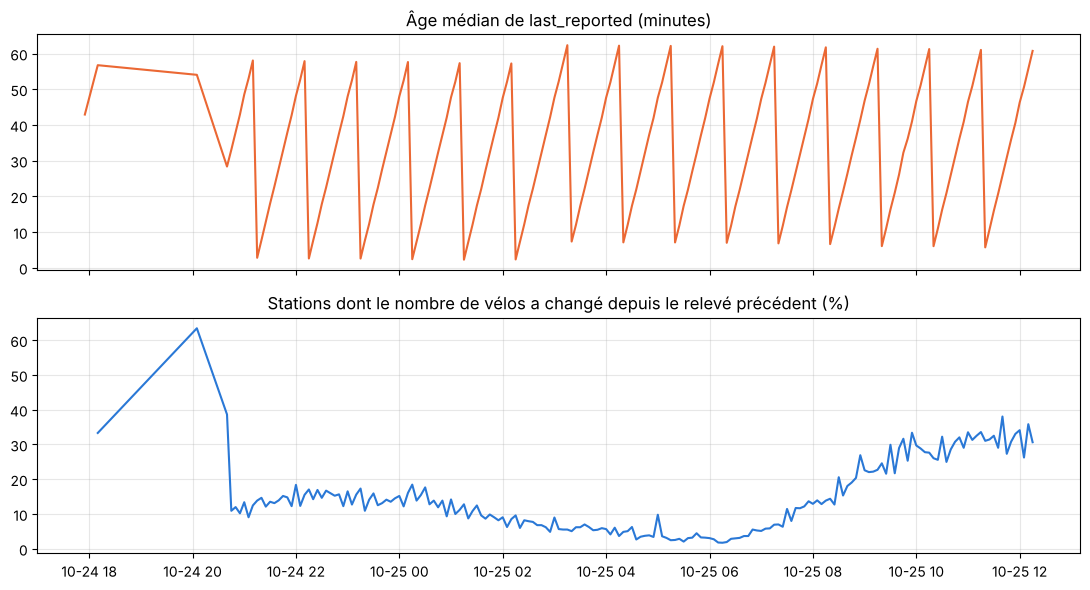

Âge médian de last_reported : 33 min
Part médiane de stations qui changent en 5 min : 12.6 %


In [13]:
df["age_last_reported_min"] = (df["collecte"] - pd.to_datetime(df["last_reported"], unit="s", utc=True)).dt.total_seconds() / 60
age_median = df.groupby("temps")["age_last_reported_min"].median()

tableau_velos = df.pivot_table(index="temps", columns="station_id", values="velos")
part_changement = ((tableau_velos.diff() != 0).mean(axis=1) * 100).iloc[1:]

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(age_median.index, age_median.values, color=ORANGE)
axes[0].set_title("Âge médian de last_reported (minutes)")
axes[1].plot(part_changement.index, part_changement.values, color=BLEU)
axes[1].set_title("Stations dont le nombre de vélos a changé depuis le relevé précédent (%)")
plt.tight_layout()
plt.show()

print(f"Âge médian de last_reported : {age_median.median():.0f} min")
print(f"Part médiane de stations qui changent en 5 min : {part_changement.median():.1f} %")

**Commentaire.** L'âge de `last_reported` monte jusqu'à environ 60 minutes puis retombe d'un coup pour toutes les stations : c'est un **signal de vie envoyé environ toutes les heures**, pas l'heure du dernier changement. Pendant ce temps, beaucoup de stations changent de nombre de vélos à chaque relevé, donc les compteurs sont bien mis à jour toutes les 5 minutes.

Conséquence : la colonne `stations_stale_over_15m` des fichiers `data/quality/` ne mesure pas la fraîcheur des données (elle vaut presque toujours 1 519). Seul un âge de plus de 24 h indique un vrai problème.

## 5. Exploration

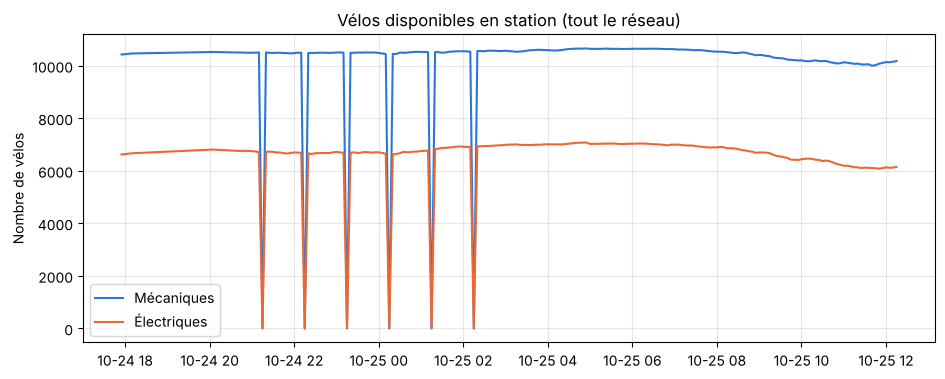

In [14]:
# 5.1 Vélos disponibles dans tout le réseau
en_service = df[df["en_service"] == 1]
total = en_service.groupby("temps")[["velos_meca", "velos_elec"]].sum()

plt.plot(total.index, total["velos_meca"], color=BLEU, label="Mécaniques")
plt.plot(total.index, total["velos_elec"], color=ORANGE, label="Électriques")
plt.title("Vélos disponibles en station (tout le réseau)")
plt.ylabel("Nombre de vélos")
plt.legend()
plt.show()

**Commentaire.** Le nombre de vélos en station baisse en journée (les vélos sont en circulation) et remonte la nuit. Il y a beaucoup moins de vélos électriques que de mécaniques en station : ils sont plus demandés et partent plus vite.

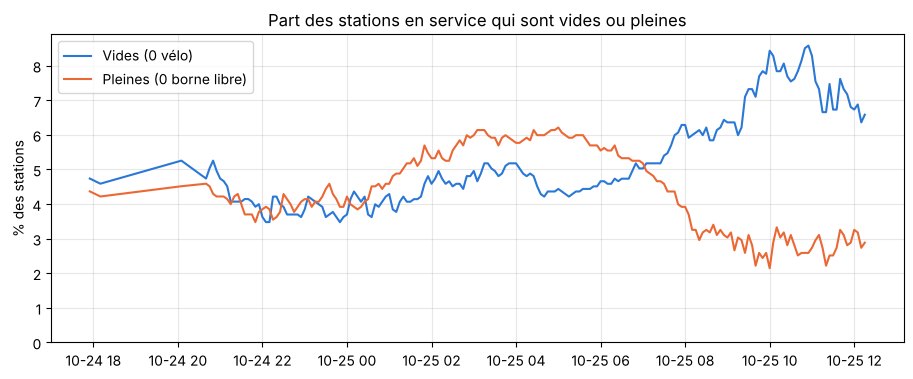

Stations vides : 5.2 % en moyenne (min 3.5 %, max 8.6 %)
Stations pleines : 4.4 % en moyenne


In [15]:
# 5.2 Part des stations vides et pleines
part = en_service.groupby("temps")[["vide", "pleine"]].mean() * 100

plt.plot(part.index, part["vide"], color=BLEU, label="Vides (0 vélo)")
plt.plot(part.index, part["pleine"], color=ORANGE, label="Pleines (0 borne libre)")
plt.title("Part des stations en service qui sont vides ou pleines")
plt.ylabel("% des stations")
plt.ylim(bottom=0)
plt.legend()
plt.show()

print(f"Stations vides : {part['vide'].mean():.1f} % en moyenne (min {part['vide'].min():.1f} %, max {part['vide'].max():.1f} %)")
print(f"Stations pleines : {part['pleine'].mean():.1f} % en moyenne")

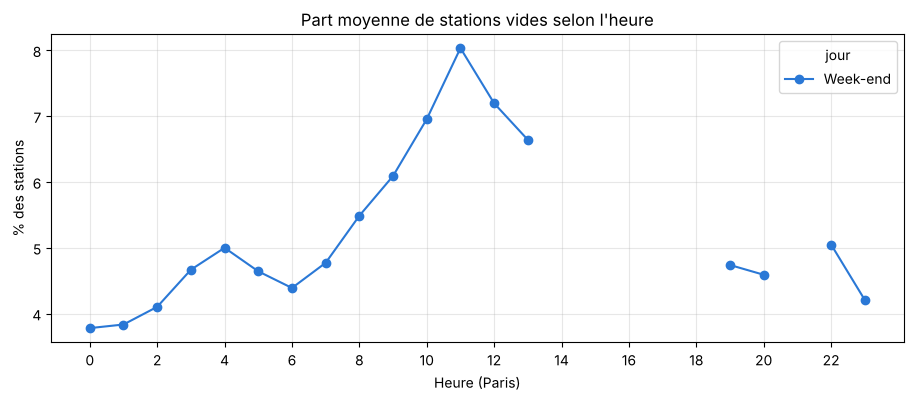

In [16]:
# 5.3 Profil selon l'heure (semaine / week-end)
part["heure"] = part.index.tz_convert("Europe/Paris").hour
part["jour"] = np.where(part.index.tz_convert("Europe/Paris").dayofweek >= 5, "Week-end", "Semaine")
profil = part.groupby(["heure", "jour"])["vide"].mean().unstack().reindex(range(24))  # heures sans données = trou dans la courbe

profil.plot(marker="o", color=[BLEU, ORANGE][: profil.shape[1]])
plt.title("Part moyenne de stations vides selon l'heure")
plt.xlabel("Heure (Paris)")
plt.ylabel("% des stations")
plt.xticks(range(0, 24, 2))
plt.show()

**Commentaire.** Ce profil repose sur peu de jours : il donne la forme du cycle de la journée, pas une moyenne fiable. Avec environ une semaine de données, on ne peut rien dire sur les saisons ou la météo.

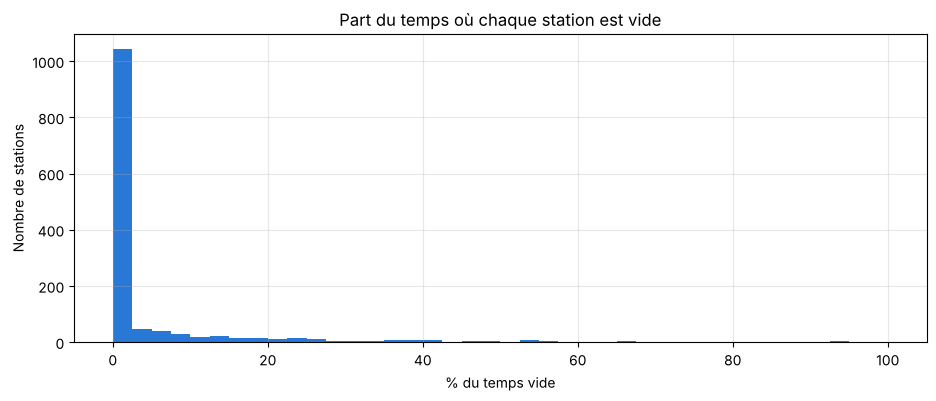

Stations jamais vides : 71%
Les 10 % de stations les plus souvent vides représentent 77% du temps vide total
Stations vides plus de 95 % du temps : 1


,name,capacity,part_temps_vide
519,Lacépède - Monge,23,1.000000
636,Louis Lumière - Porte de Bagnolet,20,0.931937
493,Haxo - Darcy,22,0.931937
964,Louis Lumière.,22,0.926702
305,Assas - Rennes,32,0.821990
1130,Paganini - Davout,22,0.806283
353,Maréchal Leclerc de Hauteclocque - Marché Buze...,30,0.790576
1166,Gare de Chaville Rive Gauche,18,0.764398
81,Faubourg Poissonnière - Dunkerque,30,0.764398
842,Sorbier - Ménilmontant,24,0.748691


In [17]:
# 5.4 Est-ce toujours les mêmes stations qui sont vides ?
par_station = en_service.groupby("station_id")["vide"].mean().to_frame("part_temps_vide")
par_station = par_station.merge(ref, on="station_id", how="left")

plt.hist(par_station["part_temps_vide"] * 100, bins=40, color=BLEU)
plt.title("Part du temps où chaque station est vide")
plt.xlabel("% du temps vide")
plt.ylabel("Nombre de stations")
plt.show()

tri = par_station.sort_values("part_temps_vide", ascending=False)
top10 = tri.head(len(tri) // 10)
print(f"Stations jamais vides : {(par_station['part_temps_vide'] == 0).mean():.0%}")
print(f"Les 10 % de stations les plus souvent vides représentent {top10['part_temps_vide'].sum() / tri['part_temps_vide'].sum():.0%} du temps vide total")
print(f"Stations vides plus de 95 % du temps : {(par_station['part_temps_vide'] > 0.95).sum()}")
tri.head(10)[["name", "capacity", "part_temps_vide"]]

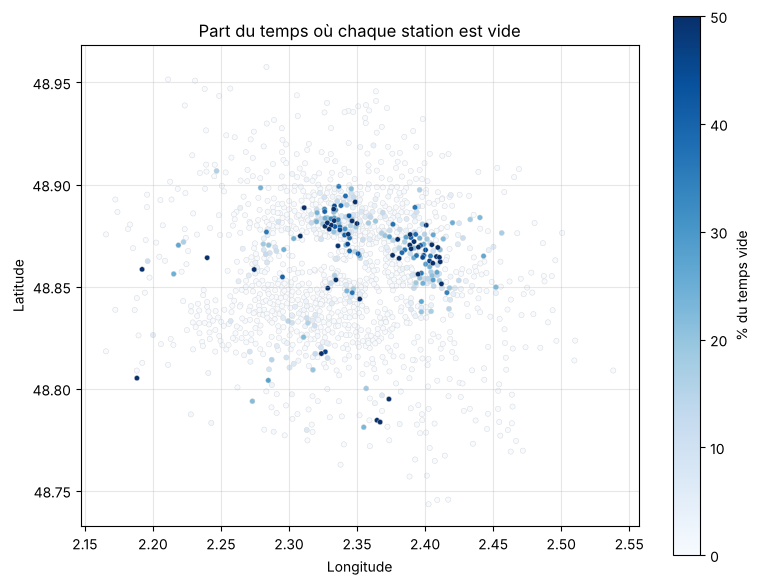

In [18]:
# 5.5 Carte des stations
carte = par_station.sort_values("part_temps_vide")   # les stations souvent vides sont dessinées par-dessus
plt.figure(figsize=(9, 7))
plt.scatter(carte["lon"], carte["lat"], c=carte["part_temps_vide"] * 100,
            cmap="Blues", s=14, vmax=50, edgecolors="lightgray", linewidths=0.3)
plt.colorbar(label="% du temps vide")
plt.title("Part du temps où chaque station est vide")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.gca().set_aspect(1.5)   # pour que Paris ne soit pas écrasé
plt.show()

**Commentaire.**
- Les stations vides sont presque toujours les mêmes : la plupart des stations ne sont jamais vides, et une petite partie concentre la majorité des ruptures.
- Quelques stations sont vides en permanence tout en étant « en service » : elles sont sans doute en panne. C'est un problème de qualité à signaler.
- Sur la carte, les stations souvent vides forment des groupes, notamment sur les hauteurs (Montmartre, Belleville–Ménilmontant) : on y descend à vélo mais on remonte rarement. À vérifier sur la semaine complète.
- Pour le modèle, l'historique de chaque station sera donc une variable utile.

## 6. Construction de la cible « vide dans 30 min »

Pour chaque station et chaque instant *t*, on va chercher l'état de la même station à *t* + 30 min avec un `merge`. On ajoute aussi des variables du passé (nombre de vélos il y a 15 et 30 minutes) pour mesurer si la station est en train de se vider. On n'utilise **jamais** d'information postérieure à *t* comme variable.

In [19]:
def decaler(df, minutes, suffixe):
    """Renvoie les vélos et l'état de service décalés dans le temps, pour les fusionner avec df."""
    copie = df[["station_id", "temps", "velos", "en_service"]].copy()
    copie["temps"] = copie["temps"] - pd.Timedelta(minutes=minutes)
    return copie.rename(columns={"velos": "velos" + suffixe, "en_service": "en_service" + suffixe})


# État dans 30 minutes (pour la cible)
data = df.merge(decaler(df, 30, "_futur"), on=["station_id", "temps"], how="inner")

# État il y a 15 et 30 minutes (variables explicatives)
data = data.merge(decaler(df, -15, "_moins15"), on=["station_id", "temps"], how="left")
data = data.merge(decaler(df, -30, "_moins30"), on=["station_id", "temps"], how="left")

# On garde les stations en service maintenant et dans 30 minutes.
data = data[(data["en_service"] == 1) & (data["en_service_futur"] == 1)].copy()
data["cible"] = (data["velos_futur"] == 0).astype(int)

print("Nombre d'exemples :", len(data))
print(f"Part de stations vides dans 30 min : {data['cible'].mean():.1%}")

Nombre d'exemples : 246045
Part de stations vides dans 30 min : 5.2%


In [20]:
# Variables explicatives
data["vide_maintenant"] = (data["velos"] == 0).astype(int)
data["taux_remplissage"] = data["velos"] / (data["velos"] + data["bornes_libres"]).replace(0, np.nan)
data["variation_15min"] = data["velos"] - data["velos_moins15"]
data["variation_30min"] = data["velos"] - data["velos_moins30"]
data["heure"] = data["temps"].dt.tz_convert("Europe/Paris").dt.hour
data["week_end"] = (data["temps"].dt.tz_convert("Europe/Paris").dt.dayofweek >= 5).astype(int)
data = data.merge(ref[["station_id", "lat", "lon"]], on="station_id", how="left")

# Valeurs manquantes (relevé passé absent) : on remplace par 0 (pas de variation connue).
for col in ["taux_remplissage", "variation_15min", "variation_30min", "velos_elec"]:
    data[col] = data[col].fillna(0)

In [21]:
# Tableau clé : que devient une station 30 minutes plus tard ?
pd.crosstab(data["vide_maintenant"], data["cible"], normalize="index").round(3) * 100

cible,0,1
vide_maintenant,,
0,98.5,1.5
1,26.4,73.6


**Commentaire.** Ce tableau résume le problème :
- une station **vide maintenant** l'est encore dans 30 minutes dans la grande majorité des cas ;
- une station **qui a des vélos** ne devient vide que dans une petite fraction des cas.

Il faut donc comparer nos modèles à une règle très simple, la **persistance** : « si la station est vide maintenant, elle sera vide dans 30 min ». La vraie difficulté est de prévoir les stations qui ont encore des vélos mais vont se vider. Comme les stations vides sont rares, l'accuracy n'a pas de sens ici (prédire « jamais vide » donnerait plus de 90 %) : on utilise la précision, le rappel, le F1 et la PR-AUC.

## 7. Modèles et évaluation

**Découpage dans l'ordre du temps.** On coupe la période en trois morceaux successifs :
- **entraînement** (60 % du temps) : pour apprendre les modèles ;
- **validation** (15 %) : pour choisir le seuil de décision ;
- **test** (25 % restants) : pour l'évaluation finale, utilisé une seule fois.

On ne mélange pas au hasard : deux relevés espacés de 5 minutes se ressemblent presque toujours, un découpage aléatoire donnerait donc des scores trop optimistes. On laisse aussi un écart de 30 minutes avant chaque coupure, pour que la cible d'une période ne tombe pas dans la période suivante.

In [22]:
t_debut = data["temps"].min()
duree = data["temps"].max() - t_debut
marge = pd.Timedelta(minutes=30)
coupure_valid = t_debut + 0.60 * duree
coupure_test = t_debut + 0.75 * duree

train = data[data["temps"] < coupure_valid - marge].copy()
valid = data[(data["temps"] >= coupure_valid) & (data["temps"] < coupure_test - marge)].copy()
test = data[data["temps"] >= coupure_test].copy()

for nom, partie in [("Entraînement", train), ("Validation", valid), ("Test", test)]:
    print(f"{nom:13}: {partie['temps'].min().tz_convert('Europe/Paris'):%d/%m %H:%M} → "
          f"{partie['temps'].max().tz_convert('Europe/Paris'):%d/%m %H:%M} | {len(partie)} lignes | "
          f"{partie['cible'].mean():.1%} de positifs")

Entraînement : 24/10 22:40 → 25/10 06:10 | 139237 lignes | 4.3% de positifs
Validation   : 25/10 06:45 → 25/10 08:25 | 28392 lignes | 5.2% de positifs
Test         : 25/10 09:00 → 25/10 12:45 | 62192 lignes | 7.2% de positifs


In [23]:
# Historique de chaque station : part du temps vide, calculée SEULEMENT sur l'entraînement.
historique = train.groupby("station_id")["vide_maintenant"].mean()
for partie in [train, valid, test]:
    partie["historique_station"] = partie["station_id"].map(historique).fillna(historique.mean())

variables = ["velos", "bornes_libres", "velos_elec", "taux_remplissage", "variation_15min",
             "variation_30min", "heure", "week_end", "historique_station", "lat", "lon"]

X_test, y_test = test[variables], test["cible"]

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             precision_recall_curve, confusion_matrix)

# Pour que l'entraînement reste rapide sur Colab, on prend au plus 300 000 lignes au hasard.
echantillon = train.sample(min(len(train), 300_000), random_state=0)

modele_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modele_lr.fit(echantillon[variables], echantillon["cible"])

modele_rf = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20,
                                   n_jobs=-1, random_state=0)
modele_rf.fit(echantillon[variables], echantillon["cible"])
print("Modèles entraînés")

Modèles entraînés


In [25]:
# Choix du seuil sur la validation.
# Par défaut, predict() prédit "vide" si la probabilité dépasse 0,5. Comme les stations vides sont rares,
# ce seuil est trop strict : on teste plusieurs seuils et on garde celui qui donne le meilleur F1.
seuils = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]
modeles = {"Régression logistique": modele_lr, "Random forest": modele_rf}
meilleur_seuil = {}
tableau_seuils = pd.DataFrame(index=seuils)

for nom, modele in modeles.items():
    proba_valid = modele.predict_proba(valid[variables])[:, 1]
    tableau_seuils[nom] = [f1_score(valid["cible"], proba_valid >= s) for s in seuils]
    meilleur_seuil[nom] = float(tableau_seuils[nom].idxmax())

print("F1 sur la validation selon le seuil :")
display(tableau_seuils.round(3))
print("Seuils retenus :", meilleur_seuil)

F1 sur la validation selon le seuil :


,Régression logistique,Random forest
0.10,0.720,0.774
0.15,0.748,0.818
0.20,0.768,0.837
0.25,0.781,0.863
0.30,0.780,0.874
0.35,0.765,0.861
0.40,0.762,0.837
0.50,0.752,0.831


Seuils retenus : {'Régression logistique': 0.25, 'Random forest': 0.3}


In [26]:
def evaluer(nom, y_vrai, y_pred, proba=None):
    resultat = {
        "modèle": nom,
        "précision": precision_score(y_vrai, y_pred, zero_division=0),
        "rappel": recall_score(y_vrai, y_pred, zero_division=0),
        "F1": f1_score(y_vrai, y_pred, zero_division=0),
    }
    if proba is not None:
        resultat["PR-AUC"] = average_precision_score(y_vrai, proba)
    return resultat


predictions = {"Persistance": (test["vide_maintenant"].to_numpy(), None)}
for nom, modele in modeles.items():
    proba_test = modele.predict_proba(X_test)[:, 1]
    predictions[nom] = ((proba_test >= meilleur_seuil[nom]).astype(int), proba_test)

# Résultats sur tout le test
resultats = pd.DataFrame([evaluer(nom, y_test, pred, proba) for nom, (pred, proba) in predictions.items()])
print("Toutes les stations du test :")
display(resultats.round(3))

# Résultats sur les stations qui ont encore des vélos : peut-on prévoir qu'elles vont se vider ?
non_vides = (test["vide_maintenant"] == 0).to_numpy()
resultats_non_vides = pd.DataFrame([
    evaluer(nom, y_test[non_vides], pred[non_vides], None if proba is None else proba[non_vides])
    for nom, (pred, proba) in predictions.items()
])
print("Stations qui ont encore des vélos maintenant :")
display(resultats_non_vides.round(3))

Toutes les stations du test :


,modèle,précision,rappel,F1,PR-AUC
0,Persistance,0.595,0.588,0.592,NaN
1,Régression logistique,0.552,0.546,0.549,0.558
2,Random forest,0.590,0.532,0.560,0.576


Stations qui ont encore des vélos maintenant :


,modèle,précision,rappel,F1,PR-AUC
0,Persistance,0.000,0.000,0.000,NaN
1,Régression logistique,0.306,0.160,0.210,0.248
2,Random forest,0.312,0.038,0.067,0.236


In [27]:
# Matrice de confusion du random forest
pd.DataFrame(confusion_matrix(y_test, predictions["Random forest"][0]),
             index=["réel : pas vide", "réel : vide"], columns=["prédit : pas vide", "prédit : vide"])

,prédit : pas vide,prédit : vide
réel : pas vide,56091,1648
réel : vide,2082,2371


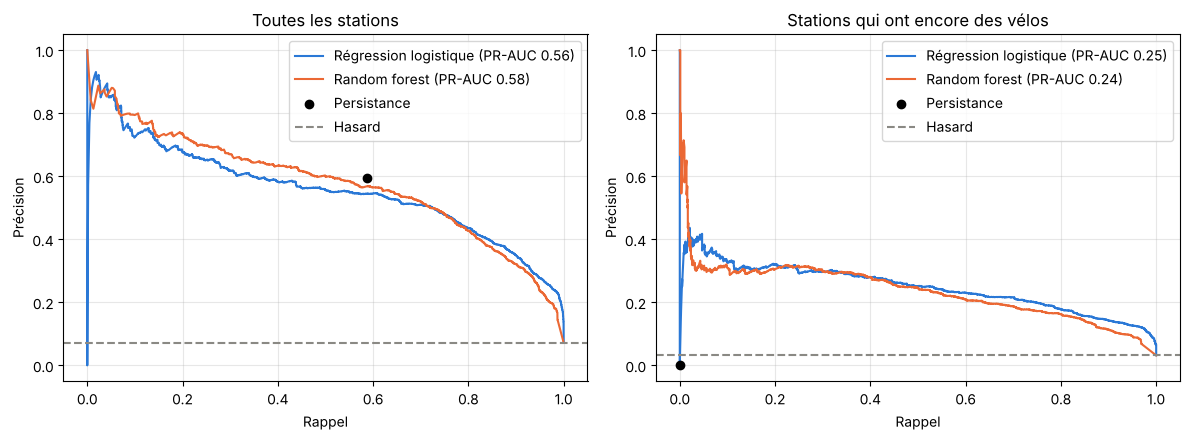

In [28]:
# Courbes précision-rappel : on voit tous les compromis possibles, pas seulement le seuil 0,5.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, masque, titre in [(axes[0], np.ones(len(y_test), dtype=bool), "Toutes les stations"),
                          (axes[1], non_vides, "Stations qui ont encore des vélos")]:
    for nom, couleur in [("Régression logistique", BLEU), ("Random forest", ORANGE)]:
        proba = predictions[nom][1][masque]
        precision, rappel, _ = precision_recall_curve(y_test[masque], proba)
        ax.plot(rappel, precision, color=couleur, label=f"{nom} (PR-AUC {average_precision_score(y_test[masque], proba):.2f})")
    p = precision_score(y_test[masque], test["vide_maintenant"][masque], zero_division=0)
    r = recall_score(y_test[masque], test["vide_maintenant"][masque], zero_division=0)
    ax.scatter(r, p, color="black", zorder=3, label="Persistance")
    ax.axhline(y_test[masque].mean(), color=GRIS, linestyle="--", label="Hasard")
    ax.set_title(titre)
    ax.set_xlabel("Rappel")
    ax.set_ylabel("Précision")
    ax.legend()
plt.tight_layout()
plt.show()

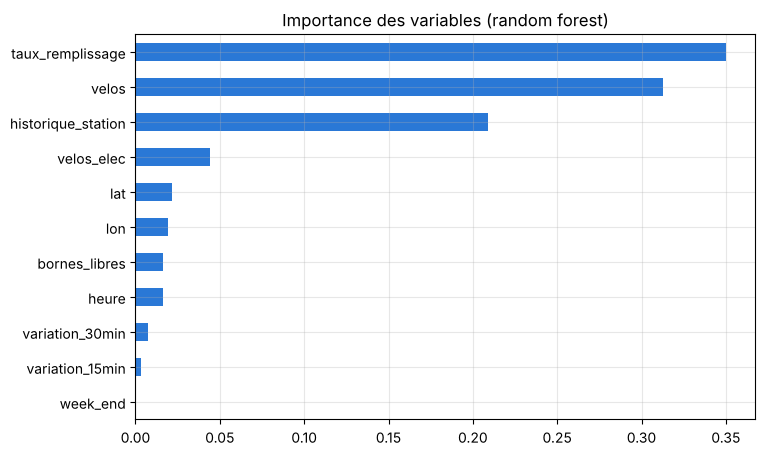

In [29]:
# Importance des variables (random forest)
importance = pd.Series(modele_rf.feature_importances_, index=variables).sort_values()
importance.plot(kind="barh", color=BLEU, figsize=(8, 5))
plt.title("Importance des variables (random forest)")
plt.show()

**Commentaire.**
- Sur **toutes les stations**, la persistance est déjà très forte, car une station vide le reste souvent plus de 30 minutes. Si un modèle ne fait pas mieux qu'elle, il n'apporte rien.
- Sur les **stations qui ont encore des vélos**, la persistance ne détecte aucune rupture (rappel = 0). C'est là que les modèles sont utiles : ils repèrent une partie des stations qui vont se vider, avec une précision bien meilleure que le hasard (ligne pointillée).
- Le seuil de décision a été choisi sur la validation. La courbe précision-rappel montre tous les autres compromis possibles : baisser le seuil détecte plus de ruptures, au prix de plus de fausses alertes. Le bon choix dépend de l'usage (une appli qui prévient l'usager préférera peu de fausses alertes).
- Si les modèles font moins bien que la persistance en F1 sur toutes les stations, c'est souvent parce que la validation est courte et ne ressemble pas au test (heures différentes) : le seuil choisi se transpose mal.
- Les variables les plus importantes sont le nombre de vélos restants (et le taux de remplissage) et l'historique de la station. Sur les premières données, la tendance récente (variation sur 15 et 30 min) compte peu : à revoir avec la semaine complète, où les heures de pointe devraient la rendre plus utile.

⚠ Avec peu de jours de données, l'entraînement ne couvre pas toutes les heures de la journée : les résultats peuvent changer nettement avec la semaine complète. Relire ces commentaires après la dernière exécution.

## 8. Conclusion et limites

In [30]:
# Chiffres clés, recalculés à chaque exécution (à reprendre dans le rapport).
print(f"Période : {debut.tz_convert('Europe/Paris'):%d/%m %H:%M} → {fin.tz_convert('Europe/Paris'):%d/%m %H:%M}, {duree_heures:.0f} h, couverture {len(releves) / attendus:.0%}")
print(f"Stations analysées : {df['station_id'].nunique()} ({len(muettes)} stations muettes retirées)")
print(f"Stations vides en moyenne : {part['vide'].mean():.1f} %")
print(f"Stations jamais vides : {(par_station['part_temps_vide'] == 0).mean():.0%}")
print(f"Vide dans 30 min si vide maintenant : {data.loc[data['vide_maintenant'] == 1, 'cible'].mean():.0%} ; si non vide : {data.loc[data['vide_maintenant'] == 0, 'cible'].mean():.1%}")
print()
print(resultats.set_index("modèle").round(2))
print()
print(resultats_non_vides.set_index("modèle").round(2))

Période : 24/10 19:55 → 25/10 13:15, 18 h, couverture 86%
Stations analysées : 1501 (18 stations muettes retirées)
Stations vides en moyenne : 5.2 %
Stations jamais vides : 71%
Vide dans 30 min si vide maintenant : 74% ; si non vide : 1.5%

                       précision  rappel    F1  PR-AUC
modèle                                                
Persistance                 0.60    0.59  0.59     NaN
Régression logistique       0.55    0.55  0.55    0.56
Random forest               0.59    0.53  0.56    0.58

                       précision  rappel    F1  PR-AUC
modèle                                                
Persistance                 0.00    0.00  0.00     NaN
Régression logistique       0.31    0.16  0.21    0.25
Random forest               0.31    0.04  0.07    0.24


### Conclusion

1. **La collecte fonctionne** : environ un relevé toutes les 5 minutes, avec quelques trous documentés. Les compteurs de vélos sont fiables ; seul `last_reported` est trompeur.
2. **Les stations vides sont rares et concentrées** : quelques pourcents des stations à un instant donné, presque toujours les mêmes, regroupées géographiquement.
3. **La persistance est difficile à battre** sur les stations déjà vides, car les ruptures durent souvent plus de 30 minutes.
4. **Les modèles servent surtout à anticiper** les ruptures des stations qui ont encore quelques vélos, surtout grâce au nombre de vélos restants et à l'historique de la station.

### Limites

- **Période courte** : environ une semaine en octobre. Pas de conclusion possible sur les saisons, la météo ou les vacances.
- **Trous de collecte** : le cron GitHub n'est pas garanti ; les relevés manqués sont perdus.
- **Un seul découpage** entraînement/validation/test : il faudrait répéter l'évaluation sur plusieurs jours pour voir si les scores sont stables.
- **Définition de « vide »** : on compte tous les vélos ensemble. Une station sans vélo électrique mais avec des mécaniques n'est pas vide pour nous, alors qu'elle peut l'être pour un usager.
- **Capacité** : la capacité officielle ne tient pas compte des bornes en panne.
- **Redistribution** : les camions de l'opérateur déplacent des vélos, ce qui crée des changements brusques impossibles à prévoir avec ces données.

**Source** : flux GBFS Vélib' Métropole (`station_status.json` et `station_information.json`), [documentation open data](https://www.velib-metropole.fr/fr/donnees-open-data-gbfs-du-service-velib-metropole).